## Testing rotational distance in either $\color{forestgreen}{\theta}$ or $\color{orchid}{\varphi}$

---

1) generate function $f$ and rotated version $g$ (in either $\theta$ or $\varphi$)
2) compute rotational distance by shifting column (slices) of the projection tensor

---

Things to check in this notebook are if the volume element is included correctly. (ignoring scaling constants for now)

---

In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### my modules
from fast_volume_align_ot import utils, plots, transforms, distances, signals

	 original


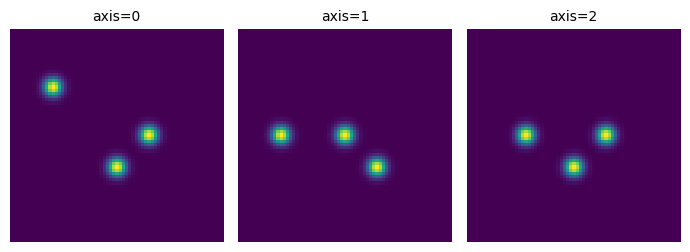

	 rotated


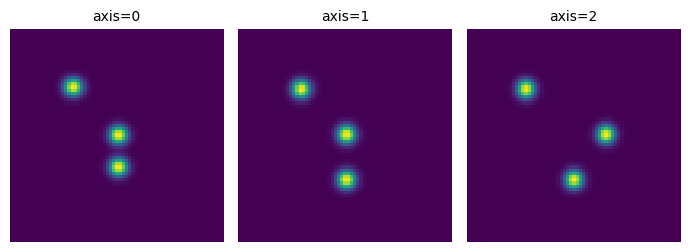

In [2]:
L = 67
sigma = 2

f = utils.generate_centered_gaussian(L=L, d=3, sigma=sigma)
f_1 = transforms.translate_3d(f, 0, 10, 0)
f_2 = transforms.translate_3d(f, 0, -15, -20)
f_3 = transforms.translate_3d(f, 10, 0, 10)
F = f_1 + f_2 + f_3

F = signals.Signal(F, d=3).preprocess_signals()[0]

thetas = np.linspace(0, np.pi, L, endpoint=True)
phis = np.linspace(0, 2*np.pi, L, endpoint=False)

omega = np.deg2rad(0)
theta = np.deg2rad(0)
phi = np.deg2rad(45)

G = transforms.rotate_voxel_zyz(F, omega, theta, phi, order=1)
G = signals.Signal(G, d=3).preprocess_signals()[0]

print('\t original')
plots.orthogonal_2D_projection_plot(F)
print('\t rotated')
plots.orthogonal_2D_projection_plot(G)

In [3]:
U = transforms.Transform(F, d=3, apply_ramp=False).inverse_cdf_transform()[0]
V = transforms.Transform(G, d=3, apply_ramp=False).inverse_cdf_transform()[0]

In [4]:
n_phi, n_points, n_theta = U.shape

dists_sw_theta = np.zeros(n_theta)
dists_sw_phi = np.zeros(n_phi)

for theta_idx in range(n_theta):
    V_theta = transforms.translate_3d(V, 0, 0, theta_idx)
    # dists_sw_theta[theta_idx] = np.mean((U - V_theta)**2)
    dists_sw_theta[theta_idx] = np.mean( np.mean( (U - V_theta)**2 , axis=1 ) * np.sin(thetas) )
    
for phi_idx in range(n_phi):
    V_phi = transforms.translate_3d(V, phi_idx, 0, 0)
    # dists_sw_phi[phi_idx] = np.mean((U - V_phi)**2)
    dists_sw_phi[phi_idx] = np.mean( np.mean( (U - V_phi)**2 , axis=1 ) * np.sin(thetas) )

dists_sw_theta = dists_sw_theta / np.amax(dists_sw_theta)
dists_sw_phi = dists_sw_phi / np.amax(dists_sw_phi)

min_theta = thetas[np.argmin(dists_sw_theta)]
min_phi = phis[np.argmin(dists_sw_phi)]

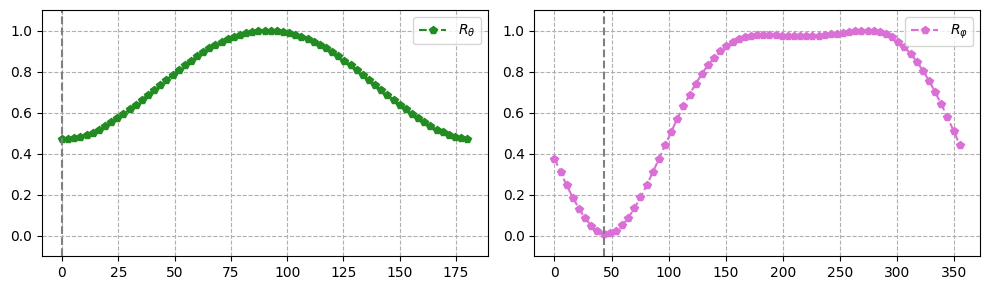

			 min_theta:  0.0 					 min_phi:  42.985
			  gt_theta:  0.0 					  gt_phi:  45.0


In [5]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3))

axs[0].plot(np.rad2deg(thetas), dists_sw_theta, 'p--', color='forestgreen', label=r'$R_\theta$')
axs[0].grid(which='major', linestyle='--')
axs[0].axvline(np.rad2deg(min_theta), linestyle='--', color='gray')
axs[0].set_ylim(-0.1, 1.1)
axs[0].legend()

axs[1].plot(np.rad2deg(phis), dists_sw_phi, 'p--', color='orchid', label=r'$R_\varphi$')
axs[1].grid(which='major', linestyle='--')
axs[1].axvline(np.rad2deg(min_phi), linestyle='--', color='gray')
axs[1].set_ylim(-0.1, 1.1)
axs[1].legend()

plt.tight_layout()
plt.show()

print('\t\t\t min_theta: ', np.round(np.rad2deg(min_theta), 3), '\t\t\t\t\t min_phi: ', np.round(np.rad2deg(min_phi), 3))
print('\t\t\t  gt_theta: ', np.round(np.rad2deg(theta), 3), '\t\t\t\t\t  gt_phi: ', np.round(np.rad2deg(phi), 3))

In [12]:
np.round(np.rad2deg(thetas), 2)

array([  0.  ,   2.73,   5.45,   8.18,  10.91,  13.64,  16.36,  19.09,
        21.82,  24.55,  27.27,  30.  ,  32.73,  35.45,  38.18,  40.91,
        43.64,  46.36,  49.09,  51.82,  54.55,  57.27,  60.  ,  62.73,
        65.45,  68.18,  70.91,  73.64,  76.36,  79.09,  81.82,  84.55,
        87.27,  90.  ,  92.73,  95.45,  98.18, 100.91, 103.64, 106.36,
       109.09, 111.82, 114.55, 117.27, 120.  , 122.73, 125.45, 128.18,
       130.91, 133.64, 136.36, 139.09, 141.82, 144.55, 147.27, 150.  ,
       152.73, 155.45, 158.18, 160.91, 163.64, 166.36, 169.09, 171.82,
       174.55, 177.27, 180.  ])

In [13]:
np.round(np.rad2deg(phis), 2)

array([  0.  ,   5.37,  10.75,  16.12,  21.49,  26.87,  32.24,  37.61,
        42.99,  48.36,  53.73,  59.1 ,  64.48,  69.85,  75.22,  80.6 ,
        85.97,  91.34,  96.72, 102.09, 107.46, 112.84, 118.21, 123.58,
       128.96, 134.33, 139.7 , 145.07, 150.45, 155.82, 161.19, 166.57,
       171.94, 177.31, 182.69, 188.06, 193.43, 198.81, 204.18, 209.55,
       214.93, 220.3 , 225.67, 231.04, 236.42, 241.79, 247.16, 252.54,
       257.91, 263.28, 268.66, 274.03, 279.4 , 284.78, 290.15, 295.52,
       300.9 , 306.27, 311.64, 317.01, 322.39, 327.76, 333.13, 338.51,
       343.88, 349.25, 354.63])